# 3 · Motion, not pixels

Notebook 2's network was asked for pixels and learned to blur: on a scrolled page it gained
1.3 dB where notebook 1's tile shift - a search, no training - gained 11.2. The shift wins
because it *copies*: a correct offset moves the content exactly. So here the output is
motion, and `current` is moved by it (`models.warp`, a `GridSample` in the graph):

- **learned motion**: notebook 2's encoder with a head that makes an offset per pixel
  instead of a correction to the picture. Starts as repeat (offset zero).
- **tile search**: notebook 1's tile shift rebuilt from fixed convolutions, so a graph can
  hold it (`models.TileSearch`): the cost of every offset within ±8 px, computed on luma at
  half the resolution, averaged over the tile, and a softmax over the costs to pick one
  motion. Nothing in it learns.
- **search + correction**: the tile search, and the learned head adding a correction per
  pixel on top - for what one motion a tile cannot follow: a cursor, a dragged window, a
  region scrolling. Starts as the tile search.

And `models.Gate`, the rule a client can apply per tile before running anything: where
nothing moved between `previous` and `current`, repeat.

Steps:

1. **Data** - as notebook 2: halo 8, and the client's 4.
2. **Models** - built, and checked to start where they should.
3. **The tile search** - untrained: how sharp, and at the client's halo.
4. **Speed** - torch, and the graph at the client's tile.
5. **Train** - the two learned models.
6. **Results** - against repeat, notebook 1's exact shift and notebook 2's network, gated
   and not; and what it looks like.
7. **Export** - the best graph that needs no training goes to `dist/`.

Needs: `00_data_preprocess.ipynb`, and `02_extrapolate_twoscale.ipynb` for its checkpoint.
Results: `summary.md`, "Motion".

In [1]:
"""Settings."""

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import metrics, models, runs, speed, training, webexport
from helpers.training import DATA_DIR, DEVICE

RUN_DIR = training.CHECKPOINT_DIR / "motion_runs"       # each training, resumable
TWOSCALE = training.CHECKPOINT_DIR / "extrapolate_twoscale.pt"   # notebook 2's network

WIDTHS, BLOCKS = (16, 32), 3     # the learned head: notebook 2's encoder
RADIUS = 4                       # the search: offsets within ±RADIUS at half resolution = ±8 px
SCALE = 2
SHARPNESS = 10.0                 # chosen in "3. The tile search"
STRIDE = 2                       # the cost sampled on every 2nd position: chosen in "4. Speed"

HALO = 8
CONTEXT, AHEAD = 2, 1
BATCH_SIZE = 64
LEARNING_RATE = 1e-4             # offsets in pixels: 1e-3 moves them too far a step
MAX_EPOCHS = 500                 # a safety limit; training stops once it has converged
SEED = 0

BENCH_SIZES = [(640, 360), (960, 540), (1280, 720), (1920, 1080)]
training.seed_everything(SEED)

## 1. Data

The same samples as notebook 2, so every number below compares with its tables.

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
train_loader = training.loader(DATA_DIR, manifest, BATCH_SIZE, CONTEXT, AHEAD, halo=HALO)

validation = {}
for halo in sorted({HALO, webexport.TILE_HALO}):
    inputs, targets = runs.load(DATA_DIR, "val", manifest, CONTEXT, AHEAD, halo=halo)
    masks = runs.groups(manifest, "val", inputs[:, -1], targets, halo)
    validation[halo] = (inputs, targets, masks)
KINDS = [kind for kind in ("page", "desktop", "photo", "video", "cursor") if kind in masks]
for halo, (_, _, masks) in validation.items():
    for kind in KINDS:
        masks[f"{kind}, changed"] = masks[kind] & masks["changed"]
inputs, targets, masks = validation[HALO]
print("val    ", inputs.shape, "->", targets.shape)

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 30 fps
run     96 px (64 px + a halo of 16), 8 frames each
train  12491 runs from 798 sources


val     (3226, 2, 80, 80, 3) -> (3226, 80, 80, 3)


## 2. Models

    learned motion        previous, current --> encoder (notebook 2) --> head --> offset per pixel
    tile search           previous, current --> luma at 1/2 --> |current - previous moved by d|, 81 offsets
                                                --> mean over the tile --> softmax --> one offset
    search + correction   tile search offset + learned offset per pixel
    then                  current --> GridSample at every pixel + its offset --> output

The search's cost is fixed convolutions and a few elementwise operators: luma of each frame
at half the resolution (a 2x2 stride-2 `Conv`), `previous` moved by every offset (one `Conv`
from 1 channel to 81, each kernel a single 1) and `current` at the kernels' centre, both
without padding so only positions where every offset reads inside the picture count, then
`Sub`, `Abs` and the mean over the tile (`ReduceMean`). `STRIDE` samples those positions on
a coarser grid - a mean needs a few thousand of them, not all.

In [3]:
def search():
    return models.TileSearch(RADIUS, SCALE, SHARPNESS, STRIDE)


builders = {
    "learned motion": lambda: models.Motion(WIDTHS, BLOCKS),
    "tile search": lambda: models.Motion(search=search(), learned=False),
    "search + correction": lambda: models.Motion(WIDTHS, BLOCKS, search=search()),
}
networks = {name: build().to(DEVICE) for name, build in builders.items()}
for name, network in networks.items():
    learned = sum(p.numel() for p in network.parameters() if p.requires_grad)
    print(f"{name:20} {learned:7,} learned parameters, {speed.operations_per_pixel(network):7,.0f} operations a pixel")

# notebook 2's network, for the tables
checkpoint = training.load_checkpoint(TWOSCALE)
twoscale = models.TwoScale(**checkpoint["arguments"]).to(DEVICE)
twoscale.load_state_dict(checkpoint["state_dict"])

learned motion        35,000 learned parameters,   5,342 operations a pixel
tile search                0 learned parameters,     479 operations a pixel
search + correction   35,000 learned parameters,   5,821 operations a pixel


<All keys matched successfully>

In [4]:
"""Before training: learned motion is repeat, and search + correction is the tile search."""

start = {name: training.evaluate(network, inputs, targets, masks, trim=HALO)
         for name, network in networks.items()}
repeat = training.evaluate(models.Repeat(), inputs, targets, masks, trim=HALO)
assert abs(start["learned motion"]["all"]["rgb"] - repeat["all"]["rgb"]) < 1e-3
assert abs(start["search + correction"]["all"]["rgb"] - start["tile search"]["all"]["rgb"]) < 1e-3
metrics.print_table({"repeat": repeat["changed"], **{name: scores["changed"] for name, scores in start.items()}})

                         wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat                   27.21    26.05    56.33    57.33     25.69   0.7312
learned motion           27.21    26.05    56.33    57.33     25.69   0.7312
tile search              31.20    30.07    58.36    59.25     29.67   0.8127
search + correction      31.20    30.07    58.36    59.25     29.67   0.8127


## 3. The tile search

The search needs no training, but it has a setting: `sharpness`, how hard the softmax
picks the cheapest offset. Soft, it averages neighbouring offsets, which lands between
pixels and blurs; hard, it is notebook 1's argmin. And a radius: ±8 px needs a halo of 8,
and the client's tiles have 4 - so the same search is scored there too, where offsets past
4 read the edge repeated.

In [5]:
"""Sharpness and stride, at a halo of 8; then radius at the client's halo of 4."""

shown = ["changed", *[f"{kind}, changed" for kind in KINDS], "unchanged"]
print(f"{'wPSNR (dB)':<22}" + "".join(f"{name.split(',')[0]:>10}" for name in shown))
for sharpness, stride in ((3, 1), (10, 1), (30, 1), (10, 2), (10, 4)):
    scores = training.evaluate(models.Motion(search=models.TileSearch(RADIUS, SCALE, sharpness, stride), learned=False),
                               inputs, targets, masks, trim=HALO)
    print(f"{f'sharpness {sharpness}, stride {stride}':<22}" + "".join(f"{scores[name]['wpsnr']:10.2f}" for name in shown))
exact = training.evaluate(models.Shift(radius=HALO, block=None), inputs, targets, masks, trim=HALO)
print(f"{'exact shift (nb 1)':<22}" + "".join(f"{exact[name]['wpsnr']:10.2f}" for name in shown))

x4, y4, masks4 = validation[webexport.TILE_HALO]
print(f"\nat the client's halo of {webexport.TILE_HALO}, changed samples")
for radius in (2, 4):
    scores = training.evaluate(models.Motion(search=models.TileSearch(radius, SCALE, SHARPNESS, STRIDE), learned=False),
                               x4, y4, masks4, trim=webexport.TILE_HALO)["changed"]
    print(f"  search ±{SCALE * radius} px: {scores['wpsnr']:.2f} dB, {scores['ssim']:.4f} SSIM-Y")
scores = training.evaluate(models.Shift(radius=webexport.TILE_HALO, block=None), x4, y4, masks4, trim=webexport.TILE_HALO)["changed"]
print(f"  exact shift ±{webexport.TILE_HALO} px (nb 1): {scores['wpsnr']:.2f} dB, {scores['ssim']:.4f} SSIM-Y")

wPSNR (dB)               changed      page   desktop     photo     video    cursor unchanged


sharpness 3, stride 1      31.29     32.50     25.33     32.57     31.36     25.12     66.15


sharpness 10, stride 1     31.39     33.44     25.40     32.08     31.26     24.94     70.63


sharpness 30, stride 1     31.31     33.48     25.34     31.66     31.21     24.84     72.08


sharpness 10, stride 2     31.20     33.05     25.23     31.83     31.17     24.98     69.56


sharpness 10, stride 4     30.86     32.49     25.27     31.27     30.94     24.75     66.31


exact shift (nb 1)         32.00     34.71     25.35     33.37     31.45     25.23     72.54

at the client's halo of 4, changed samples


  search ±4 px: 30.06 dB, 0.7894 SSIM-Y


  search ±8 px: 30.59 dB, 0.8109 SSIM-Y


  exact shift ±4 px (nb 1): 30.45 dB, 0.7930 SSIM-Y


## 4. Speed

In torch on this computer's GPU, one stream frame - where the search finds one motion for
the whole frame, not per tile, so it is only a cost. Then the graph the client would run, at
its 328x188 tile, on the desktop CPU.

**In the browser** (`../upscale/benchmark/main.py --models <folder>`, which feeds every input
a graph has; Chrome 156 headless, WebGPU, RTX 3090, GPU-resident tensors, the output buffer
reused; GPU time from timestamp queries), one 1080p stream frame - 36 tiles in one batch:

| graph | GPU ms a 1080p frame |
| --- | --- |
| linear (the mock) | 0.25 |
| two-scale network (notebook 2) | 3.6 |
| tile search, the first form (a 162-channel 9x9 `Conv` of two taps each) | 13.9 |
| tile search, stride 1 | 5.7 |
| **tile search, stride 2** | **2.2-2.4** |
| tile search, stride 4 | 1.4 |
| tile search + correction, the first form | 16.8 |

Every operator ran on the GPU, `GridSample` included - wall clock and GPU time agree. The
first form spent its time on a dense convolution whose kernels were 2 taps in 81; moving
`previous` with one 1-to-81 `Conv` and subtracting is the same arithmetic for a quarter of
the work, and a stride of 2 a quarter again. Stride 2 is chosen: under notebook 2's network
in time, and 0.2 dB under stride 1 on these 80 px samples, whose inner tile has 16x16
positions at stride 2 - the client's 328x188 tile has 78x43.

In [6]:
print(f"{'frame':>11}" + "".join(f"{name:>22}" for name in networks))
with torch.no_grad():
    for width, height in BENCH_SIZES:
        previous, current = torch.rand(2, 1, 3, height, width, device=DEVICE)
        row = [speed.time_ms(lambda n=network: n.eval()(previous, current), seconds=0.5) for network in networks.values()]
        print(f"{f'{width}x{height}':>11}" + "".join(f"{ms:22.2f}" for ms in row))
print("ms per frame")

for name, network in networks.items():
    info = webexport.export(network, f"speed_check_{name.replace(' ', '_').replace('+', 'and')}.onnx",
                            webexport.TILE_INPUT, models_dir=training.CHECKPOINT_DIR / "speed")
    print(webexport.summary_line(info, webexport.time_graph(info["path"], webexport.TILE_INPUT)))

      frame        learned motion           tile search   search + correction


    640x360                  0.75                  0.44                  0.89


    960x540                  0.69                  0.48                  0.99


   1280x720                  1.06                  0.56                  1.43


  1920x1080                  2.32                  1.03                  3.07
ms per frame


speed_check_learned_motion.onnx                       144.0 KB    2.33 ms   Addx4, Concatx3, Constantx14, Convx6, DepthToSpacex2, Gatherx2, GridSamplex1, LeakyRelux5, Mulx4, Reciprocalx2, Subx2, Unsqueezex2   OUTSIDE BUDGET: Gather, GridSample, Mul, Reciprocal, Sub, Unsqueeze


speed_check_tile_search.onnx                           34.0 KB    1.38 ms   Absx1, Addx4, Concatx1, Constantx21, ConstantOfShapex1, Convx4, Equalx1, Expandx1, Gatherx2, GridSamplex1, MatMulx1, Mulx7, Reciprocalx2, ReduceMeanx1, Softmaxx1, Subx3, Unsqueezex4, Wherex1   OUTSIDE BUDGET: Abs, ConstantOfShape, Equal, Expand, Gather, GridSample, MatMul, Mul, Reciprocal, ReduceMean, Softmax, Sub, Unsqueeze, Where


speed_check_search_and_correction.onnx                172.8 KB    2.39 ms   Absx1, Addx5, Concatx3, Constantx18, Convx10, DepthToSpacex2, Gatherx2, GridSamplex1, LeakyRelux5, MatMulx1, Mulx6, Reciprocalx2, ReduceMeanx1, Softmaxx1, Subx3, Unsqueezex4   OUTSIDE BUDGET: Abs, Gather, GridSample, MatMul, Mul, Reciprocal, ReduceMean, Softmax, Sub, Unsqueeze


## 5. Train

The two learned models, with the loss of notebook 2 (`metrics.luma_chroma_l1`) on the
picture the warp makes. The epoch kept is the one with the best **wPSNR** on the changed
samples, not SSIM as in notebook 2: a warp that drifts a fraction of a pixel blurs, and in
the prototypes SSIM-Y barely moved while wPSNR on scrolled pages fell by 5 dB. The learning
rate is 1e-4: at 1e-3 every step moves the offsets of every pixel a visible fraction of a
pixel.

Search + correction starts as the tile search, so its untrained score is the bar: if no
epoch beats it, the correction has learned nothing worth keeping, and `train` says so.


learned motion


Loaded the training saved in /home/henrik/desktop-streamer-ai/src/frame_gen_extra/checkpoints/motion_runs/learned_motion_halo8.pt: 164 epochs done in 6.6 min, best epoch 134 (val_changed_wpsnr: 28.0193), learning rate now 1.0e-06.
It had finished (converged - no improvement in 6 epochs, even at the smallest learning rate), so nothing is trained again - delete the file to train from the start.
Restoring model weights from the end of the best epoch: 134 (val_changed_wpsnr: 28.0193, +0.8133 over repeat). Training took 164 epochs, 6.6 min.

search + correction


Training until the model stops improving, at most 500 epochs. Untrained model (repeat): val_changed_wpsnr: 31.1987.
The training is saved to /home/henrik/desktop-streamer-ai/src/frame_gen_extra/checkpoints/motion_runs/search_and_correction_halo8.pt after every epoch.
Epoch 1/500


6/195 [>.............................] - 1s 93ms/step - loss: 0.0193

15/195 [==>...........................] - 1s 74ms/step - loss: 0.0166

...

195/195 [==============================] - 2s 12ms/step - loss: 0.0169 - val_changed_ssim_y: 0.8130 - val_changed_wpsnr: 29.6959 - val_unchanged_wpsnr: 62.6246 - learning_rate: 1.0e-06
Epoch 47: val_changed_wpsnr did not improve from 31.1987 (5 of 6 epochs without improvement)
Epoch 48/500


54/195 [========>.....................] - 1s 9ms/step - loss: 0.0176

108/195 [================>.............] - 1s 9ms/step - loss: 0.0171

161/195 [========================>.....] - 2s 9ms/step - loss: 0.0170

195/195 [==============================] - 2s 12ms/step - loss: 0.0171 - val_changed_ssim_y: 0.8130 - val_changed_wpsnr: 29.6943 - val_unchanged_wpsnr: 62.6581 - learning_rate: 1.0e-06
Epoch 48: val_changed_wpsnr did not improve from 31.1987 (6 of 6 epochs without improvement)
Epoch 48: stopping (converged - no improvement in 6 epochs, even at the smallest learning rate)
Restoring model weights from the end of the best epoch: 0 (val_changed_wpsnr: 31.1987, +0.0000 over repeat). Training took 48 epochs, 2.0 min.


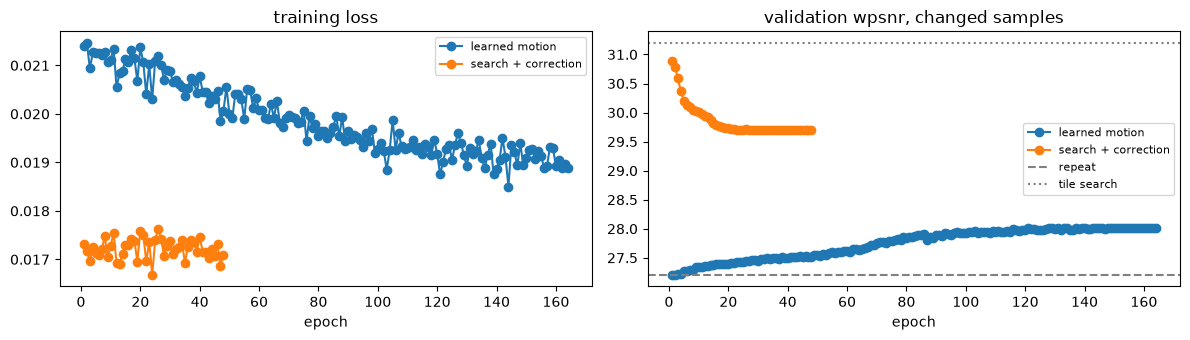

In [7]:
histories, bests = {}, {}
for name in ("learned motion", "search + correction"):
    print(f"\n{'=' * 100}\n{name}\n{'=' * 100}")
    training.seed_everything(SEED)
    histories[name], bests[name] = training.train(
        networks[name], train_loader, validation[HALO], HALO, MAX_EPOCHS, learning_rate=LEARNING_RATE,
        select=("changed", "wpsnr"), checkpoint=RUN_DIR / f"{name.replace(' ', '_').replace('+', 'and')}_halo{HALO}.pt")
training.plot_history(histories, {"repeat": repeat, "tile search": start["tile search"]}, key="wpsnr")

## 6. Results

Every model, ungated and gated: by group, by kind of source, and at the client's halo.

In [8]:
contenders = {"repeat": models.Repeat(), "linear (mock)": models.Blend(1.0),
              "exact shift (nb 1)": models.Shift(radius=HALO, block=None),
              "two-scale (nb 2)": twoscale, **networks}
results = {name: training.evaluate(model, inputs, targets, masks, trim=HALO) for name, model in contenders.items()}
for name in ("two-scale (nb 2)", "tile search", "search + correction"):
    results[f"{name}, gated"] = training.evaluate(models.Gate(contenders[name]), inputs, targets, masks, trim=HALO)

for group in ("changed", "unchanged", "all"):
    print(f"\n{group}: {masks[group].sum()} samples, halo {HALO}")
    metrics.print_table({name: scores[group] for name, scores in results.items()},
                        extra=lambda name, s, g=group: f"   {s['wpsnr'] - results['repeat'][g]['wpsnr']:+6.2f} dB vs repeat")


changed: 1852 samples, halo 8
                                wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat                          27.21    26.05    56.33    57.33     25.69   0.7312    +0.00 dB vs repeat
linear (mock)                   24.74    23.59    53.48    54.36     23.23   0.6728    -2.47 dB vs repeat
exact shift (nb 1)              32.00    30.95    58.67    59.56     30.36   0.8180    +4.79 dB vs repeat
two-scale (nb 2)                28.35    27.23    51.67    53.11     26.73   0.7628    +1.14 dB vs repeat
learned motion                  28.02    26.87    56.83    57.76     26.50   0.7651    +0.81 dB vs repeat
tile search                     31.20    30.07    58.36    59.25     29.67   0.8127    +3.99 dB vs repeat
search + correction             31.20    30.07    58.36    59.25     29.67   0.8127    +3.99 dB vs repeat
two-scale (nb 2), gated         28.35    27.23    52.00    53.53     26.73   0.7627    +1.14 dB vs repeat
tile search, gated              31.20

In [9]:
"""By kind of source (changed samples); and the models at the client's halo."""

for key, label, digits in (("ssim", "SSIM-Y", 4), ("wpsnr", "wPSNR (dB)", 2)):
    print(f"{label + ', changed':<28}" + "".join(f"{kind:>10}" for kind in KINDS))
    for name, scores in results.items():
        if "gated" in name:
            continue
        print(f"{name:<28}" + "".join(f"{scores[f'{kind}, changed'][key]:10.{digits}f}" for kind in KINDS))
    print()

small = webexport.TILE_HALO
print(f"{'changed samples':<28}{f'halo {HALO}':>18}{f'halo {small}':>18}")
print(f"{'':<28}" + f"{'SSIM-Y':>9}{'wPSNR':>9}" * 2)
for name in ("repeat", "exact shift (nb 1)", "two-scale (nb 2)", *networks):
    model = models.Shift(radius=small, block=None) if name == "exact shift (nb 1)" else contenders[name]
    narrow = training.evaluate(model, x4, y4, masks4, trim=small)["changed"]
    wide = results[name]["changed"]
    print(f"{name:<28}{wide['ssim']:9.4f}{wide['wpsnr']:9.2f}{narrow['ssim']:9.4f}{narrow['wpsnr']:9.2f}")

SSIM-Y, changed                   page   desktop     photo     video    cursor
repeat                          0.6418    0.7817    0.5479    0.8225    0.7148
linear (mock)                   0.5900    0.7384    0.4872    0.7590    0.6634
exact shift (nb 1)              0.7733    0.7564    0.8220    0.8494    0.7553
two-scale (nb 2)                0.6668    0.7804    0.6638    0.8367    0.7331
learned motion                  0.6983    0.7810    0.6368    0.8344    0.7182
tile search                     0.7630    0.7580    0.8137    0.8462    0.7539
search + correction             0.7630    0.7580    0.8137    0.8462    0.7539

wPSNR (dB), changed               page   desktop     photo     video    cursor
repeat                           23.53     25.81     24.28     30.14     24.20
linear (mock)                    20.57     22.98     21.47     28.08     21.50
exact shift (nb 1)               34.71     25.35     33.37     31.45     25.23
two-scale (nb 2)                 24.86     26.29   

repeat                         0.7312    27.21   0.7312    27.21


exact shift (nb 1)             0.8180    32.00   0.7930    30.45


two-scale (nb 2)               0.7628    28.35   0.7625    28.29


learned motion                 0.7651    28.02   0.7640    27.87


tile search                    0.8127    31.20   0.8109    30.59


search + correction            0.8127    31.20   0.8109    30.59


### What it looks like

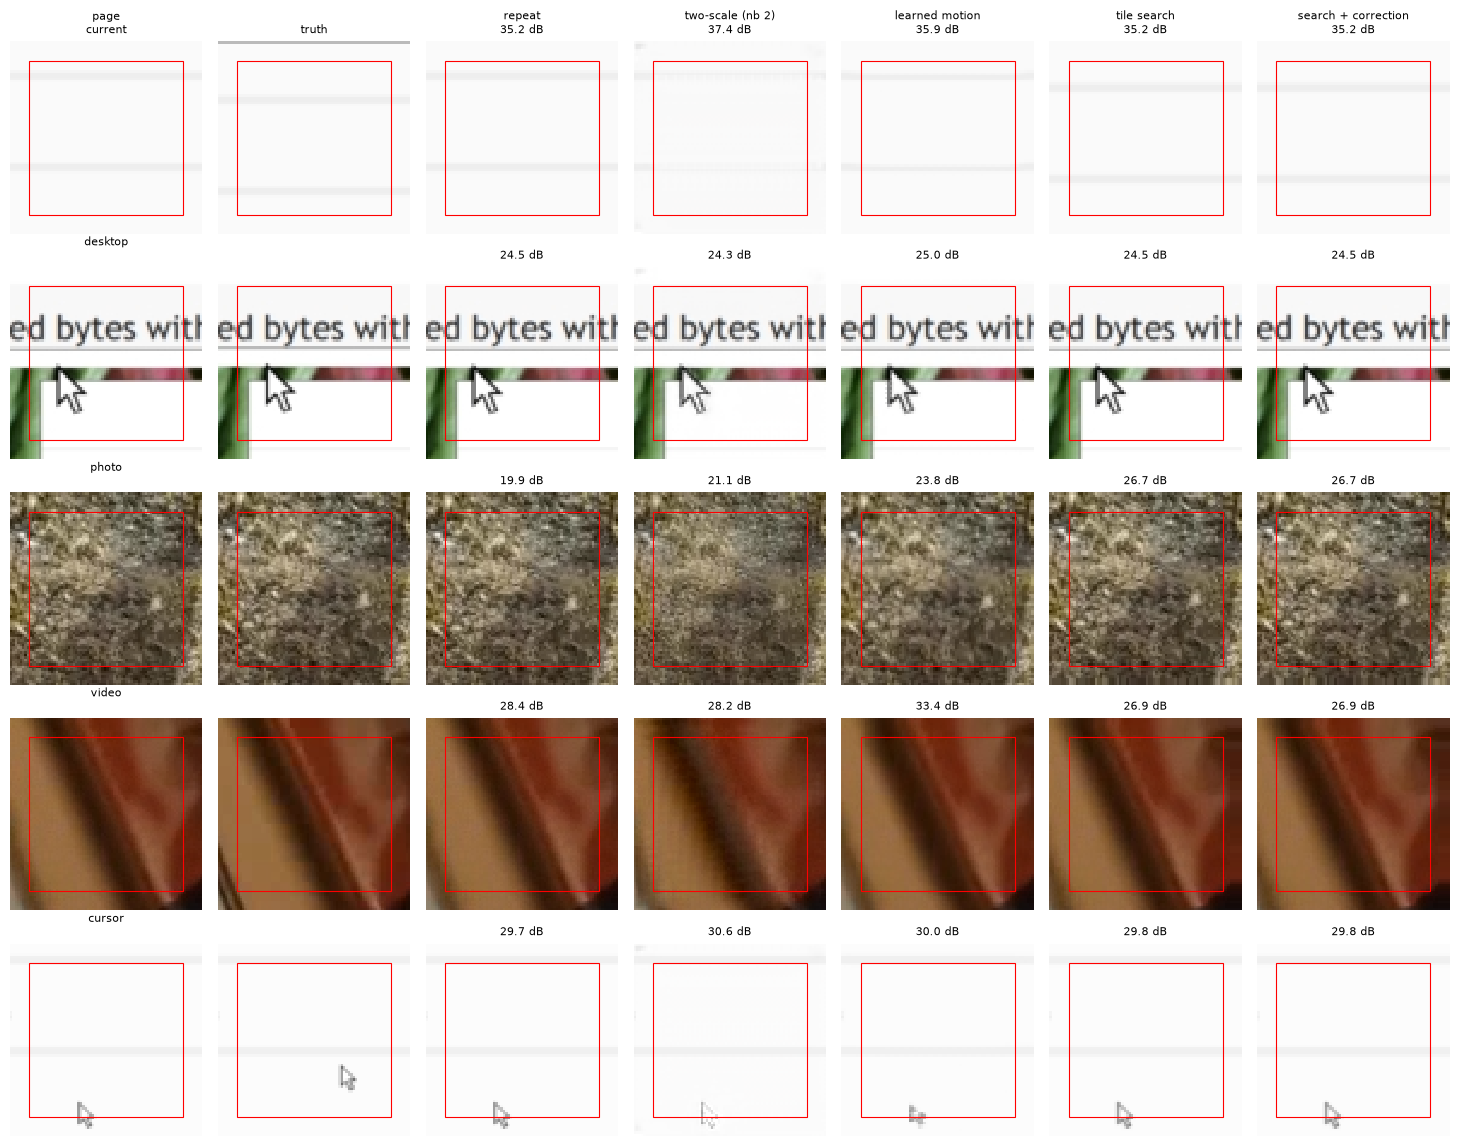

In [10]:
pick_rng = np.random.default_rng(SEED)
picks = [(kind, int(pick_rng.choice(np.flatnonzero(masks[f"{kind}, changed"]))))
         for kind in KINDS if masks[f"{kind}, changed"].any()]
shown_models = {"repeat": models.Repeat(), "two-scale (nb 2)": twoscale.eval(),
                **{name: network.eval() for name, network in networks.items()}}

columns = ["current", "truth", *shown_models]
fig, axes = plt.subplots(len(picks), len(columns), figsize=(2.1 * len(columns), 2.3 * len(picks)), squeeze=False)
for row, (kind, index) in enumerate(picks):
    sample = training.to_tensor(inputs[index:index + 1])
    truth = training.to_tensor(targets[index:index + 1])
    pictures = {"current": sample[:, 1], "truth": truth}
    with torch.no_grad():
        for name, model in shown_models.items():
            pictures[name] = model(sample[:, 0], sample[:, 1]).clamp(0, 1)
    for column, name in enumerate(columns):
        ax = axes[row][column]
        ax.imshow(pictures[name][0].permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
        ax.add_patch(plt.Rectangle((HALO - 0.5, HALO - 0.5), manifest["core"], manifest["core"],
                                   fill=False, color="red", lw=0.8))
        title = name if row == 0 else ""
        if name in shown_models:
            score = metrics.wpsnr(runs.trim(pictures[name], HALO), runs.trim(truth, HALO))
            title = f"{title}\n{score:.1f} dB" if title else f"{score:.1f} dB"
        if column == 0:
            title = f"{kind}\n{title}"
        ax.set_title(title, fontsize=8)
        ax.axis("off")
fig.tight_layout()
plt.show()

## 7. Export for the client

The tile search needs no training, so its graph is the model: at the client's tile (a
320x180 step and a halo of 4), with the mock's two inputs, checked against torch, into
`dist/frame_gen_extra/` - once a tile a run, and once as the 36 tiles of a 1080p frame in one
run, which is how the client runs a frame. The search + correction model goes there too only
if it beat the search; otherwise its graph stays in `checkpoints/`.

Run it with the client's gate: compare `previous` and `current` per tile first, and repeat
the tile without running anything where they match.

In [11]:
step_h, step_w = webexport.TILE_STEP
gain = results["search + correction"]["changed"]["wpsnr"] - results["tile search"]["changed"]["wpsnr"]
FRAME_TILES = 36    # a 1080p stream frame in the client's tiles, run as one batch
search_name = f"tilesearch_r{RADIUS}_s{STRIDE}"
corrected = webexport.MODELS_DIR if gain > 0.05 else training.CHECKPOINT_DIR / "export"
exports = {f"extrapolate_{search_name}_tile{step_w}x{step_h}.onnx":
               ("tile search", f"tile search ±{SCALE * RADIUS} px, stride {STRIDE}", webexport.MODELS_DIR, 1),
           f"extrapolate_{search_name}_tile{step_w}x{step_h}_b{FRAME_TILES}.onnx":
               ("tile search", f"tile search ±{SCALE * RADIUS} px, stride {STRIDE} · 1080p frame", webexport.MODELS_DIR, FRAME_TILES),
           f"extrapolate_search_correction_r{RADIUS}_s{STRIDE}_tile{step_w}x{step_h}.onnx":
               ("search + correction", f"tile search ±{SCALE * RADIUS} px + correction", corrected, 1)}
for filename, (name, label, folder, batch) in exports.items():
    module = networks[name].cpu().eval()
    info = webexport.export(module, filename, webexport.TILE_INPUT, label=label, batch=batch, models_dir=folder)
    example = np.random.rand(2, batch, 3, *webexport.TILE_INPUT).astype(np.float32)
    webexport.check_graph(info["path"], module, *example)
    ms = webexport.time_graph(info["path"], webexport.TILE_INPUT, batch=batch)
    webexport.annotate(info, cpu_ms=round(ms, 2), gate="repeat where previous and current match")
    print(webexport.summary_line(info, ms))
    print(f"  -> {folder}")
print(f"\nsearch + correction against the search alone: {gain:+.2f} dB on the changed samples")

extrapolate_tilesearch_r4_s2_tile320x180.onnx          34.1 KB    1.46 ms   Absx1, Addx4, Concatx1, Constantx21, ConstantOfShapex1, Convx4, Equalx1, Expandx1, Gatherx2, GridSamplex1, MatMulx1, Mulx7, Reciprocalx2, ReduceMeanx1, Softmaxx1, Subx3, Unsqueezex4, Wherex1   OUTSIDE BUDGET: Abs, ConstantOfShape, Equal, Expand, Gather, GridSample, MatMul, Mul, Reciprocal, ReduceMean, Softmax, Sub, Unsqueeze, Where
  -> /home/henrik/desktop-streamer-ai/dist/frame_gen_extra


extrapolate_tilesearch_r4_s2_tile320x180_b36.onnx      34.1 KB   62.00 ms   Absx1, Addx4, Concatx1, Constantx21, ConstantOfShapex1, Convx4, Equalx1, Expandx1, Gatherx2, GridSamplex1, MatMulx1, Mulx7, Reciprocalx2, ReduceMeanx1, Softmaxx1, Subx3, Unsqueezex4, Wherex1   OUTSIDE BUDGET: Abs, ConstantOfShape, Equal, Expand, Gather, GridSample, MatMul, Mul, Reciprocal, ReduceMean, Softmax, Sub, Unsqueeze, Where
  -> /home/henrik/desktop-streamer-ai/dist/frame_gen_extra


extrapolate_search_correction_r4_s2_tile320x180.onnx  172.8 KB    2.56 ms   Absx1, Addx5, Concatx3, Constantx18, Convx10, DepthToSpacex2, Gatherx2, GridSamplex1, LeakyRelux5, MatMulx1, Mulx6, Reciprocalx2, ReduceMeanx1, Softmaxx1, Subx3, Unsqueezex4   OUTSIDE BUDGET: Abs, Gather, GridSample, MatMul, Mul, Reciprocal, ReduceMean, Softmax, Sub, Unsqueeze
  -> /home/henrik/desktop-streamer-ai/src/frame_gen_extra/checkpoints/export

search + correction against the search alone: +0.00 dB on the changed samples
